CD704: Exercises, Week 5
3 November 2026

You may need LLM / AI help for the following exercises.


# Exercise 1 (When Validation Fails). 

Generate a single-feature dataset where instances
$x ∼ \mathcal{N} (0, 1)$ and the true relationship is $y = 2x+\epsilon$. 

Create two separate target variables:
$y_{\text{norm}}$ where $\epsilon ∼ \mathcal{N} (0, 1)$, and $y_{\text{cauchy}}$ where $\epsilon$ follows a standard Cauchy distribution.

1. For dataset sizes N growing from 10 to 10000 (e.g., on logarithmic scale), fit a
LinearRegression model on a training set and evaluate the MSE on a test set. Do this for both targets.

2. Plot the test MSE against the dataset size N for the normal and Cauchy error data.
Compare the two plots.

## Respones

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import pandas as pd

def lr_mse(X, y):
    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    # Fit a linear regression model
    lr = LinearRegression().fit(X_train, y_train)
    # Predict on the test set
    y_pred = lr.predict(X_test)
    # Calculate the mean squared error
    mse = mean_squared_error(y_test, y_pred)
    return mse


generator = np.random.default_rng(seed=42)  # Set a seed for reproducibility
output = pd.DataFrame(columns=['N', 'MSE_Normal', 'MSE_Cauchy'])

for exp in range(100, 600, 1):
    N = int(np.floor(10**(exp/100)))
    x_base = generator.standard_normal(N)
    y_base = 2 * x_base

    sigma_norm = generator.standard_normal(N)
    y_norm = y_base + sigma_norm
    lr_mse_norm = lr_mse(x_base.reshape(-1, 1), y_norm)

    sigma_cauchy = generator.standard_cauchy(N)
    y_cauchy = y_base + sigma_cauchy
    lr_mse_cauchy = lr_mse(x_base.reshape(-1, 1), y_cauchy)

    output = pd.concat([output, pd.DataFrame([{'N': N, 'MSE_Normal': lr_mse_norm, 'MSE_Cauchy': lr_mse_cauchy}])], ignore_index=True)

# Plotting the results as scatter plots with logarithmic scales
plt.figure(figsize=(10, 6))
plt.scatter(output['N'], output['MSE_Normal'], label='Normal Noise', color='blue', alpha=0.6)
plt.scatter(output['N'], output['MSE_Cauchy'], label='Cauchy Noise', color='red', alpha=0.6)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Number of Samples (N)')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE of Linear Regression with Normal vs Cauchy Noise')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.savefig('mse_comparison.png')

# Exercise 2 (Comparing Cross-Validation Strategies). 

Different cross-validation strategies offer different trade-offs between computational cost, bias, and variance.

1. Generate a synthetic dataset using make classification from scikit-learn (e.g., 200 instances, 10 features).

2. Evaluate the accuracy of a 3-Nearest Neighbours model using three different CV strategies from scikit-learn:
    1. Standard 5-Fold CV (KFold with shuffle=True).
    2. Monte-Carlo CV (ShuffleSplit with test size=0.2 and with n splits=5, n splits=20 and n splits=50).
    3. Repeated 5-Fold CV (RepeatedKFold with n repeats=10).

3. To see the variance of the CV estimates themselves, write a loop to repeat the
evaluations in the previous step 100 times (changing the random state of the CV
splitters each time, but keeping the underlying dataset the same). Store the mean
accuracy of each run. (You may record the running times as well.) Plot the distributions (using boxplots or histograms) of the mean accuracy scores for each of
the five CV strategies. Which strategy exhibits the widest spread, and which is the
most stable? Do you see any bias?

4. (open-ended extra question) Try to see changes when you use fewer instances or
more features.

## Respones


### Running Many Cross-Validations

In [ ]:
from sklearn.datasets import make_classification
from w5_utils import execute_kf_cv, execute_mc_cv, execute_rkf_cv
import pandas as pd

rkf_repeats = 10
mc_test_size = 0.2
mc_n_splits_five = 5
mc_n_splits_twenty = 20
mc_n_splits_fifty = 50

num_iterations = 50

# range(6, 11) for n_samples (2^6 to 2^10)
n_samples_list = [ 2**j for j in range(6, 13) ]
print(f"n_samples_list: {n_samples_list}")

# range(3, 8) for n_features (2^3 to 2^7)
n_features_list = [ 2**j for j in range(3, 8) ]
print(f"n_features_list: {n_features_list}")

output = pd.DataFrame(columns=['N_Samples', 'N_Features', 'CV_Strategy', 'MSE'])

cv_strategies = [
    'K-Fold CV',
    'Monte Carlo CV (5 splits)',
    'Monte Carlo CV (20 splits)',
    'Monte Carlo CV (50 splits)',
    'Repeated K-Fold CV'
]

elapsed_times = {strategy: 0.0 for strategy in cv_strategies}

for n_samples in n_samples_list:
    for n_features in n_features_list:
        X, y = make_classification(n_samples=n_samples, n_features=n_features, random_state=42)

        # Execute the different CV strategies
        start_time = pd.Timestamp.now().timestamp() * 1000
        mse_kfold_cv = execute_kf_cv(X, y, num_iterations)
        elapsed_times['K-Fold CV'] += (pd.Timestamp.now().timestamp() * 1000 - start_time)
        
        start_time = pd.Timestamp.now().timestamp() * 1000
        mse_mc_five_cv = execute_mc_cv(X, y, num_iterations, mc_n_splits_five)
        elapsed_times['Monte Carlo CV (5 splits)'] += (pd.Timestamp.now().timestamp() * 1000 - start_time)
        
        start_time = pd.Timestamp.now().timestamp() * 1000
        mse_mc_twenty_cv = execute_mc_cv(X, y, num_iterations, mc_n_splits_twenty)
        elapsed_times['Monte Carlo CV (20 splits)'] += (pd.Timestamp.now().timestamp() * 1000 - start_time)
        
        start_time = pd.Timestamp.now().timestamp() * 1000
        mse_mc_fifty_cv = execute_mc_cv(X, y, num_iterations, mc_n_splits_fifty)
        elapsed_times['Monte Carlo CV (50 splits)'] += (pd.Timestamp.now().timestamp() * 1000 - start_time)
        
        start_time = pd.Timestamp.now().timestamp() * 1000
        mse_rkfold_cv = execute_rkf_cv(X, y, num_iterations, rkf_repeats)
        elapsed_times['Repeated K-Fold CV'] += (pd.Timestamp.now().timestamp() * 1000 - start_time)

        mse_kfold_cv_floats = [float(mse) for mse in mse_kfold_cv]
        mse_mc_five_cv_floats = [float(mse) for mse in mse_mc_five_cv]
        mse_mc_twenty_cv_floats = [float(mse) for mse in mse_mc_twenty_cv]
        mse_mc_fifty_cv_floats = [float(mse) for mse in mse_mc_fifty_cv]
        mse_rkfold_cv_floats = [float(mse) for mse in mse_rkfold_cv]

        cv_results = {
            'K-Fold CV': mse_kfold_cv_floats,
            'Monte Carlo CV (5 splits)': mse_mc_five_cv_floats,
            'Monte Carlo CV (20 splits)': mse_mc_twenty_cv_floats,
            'Monte Carlo CV (50 splits)': mse_mc_fifty_cv_floats,
            'Repeated K-Fold CV': mse_rkfold_cv_floats
        }

        output = pd.concat([output, pd.DataFrame([{
            'N_Samples': n_samples, 
            'N_Features': n_features, 
            'CV_Strategy': key, 
            'MSE': mse} 
                for key, mse in cv_results.items()])], 
            ignore_index=True)

# Write the output DataFrame to a CSV file
output.to_csv('cv_mse_results.csv', index=False)

print(f"elapsed_times: {elapsed_times}")


Output from above...

n_samples_list: [64, 128, 256, 512, 1024, 2048, 4096]
n_features_list: [8, 16, 32, 64, 128]
elapsed_times: {
    'K-Fold CV': 30002.927734375, 
    'Monte Carlo CV (5 splits)': 30752.310302734375, 
    'Monte Carlo CV (20 splits)': 128209.7705078125, 
    'Monte Carlo CV (50 splits)': 288206.6008300781, 
    'Repeated K-Fold CV': 302353.96484375}

<table>
<tr><td><b>Cross-Validation Strategy</b><td><b>Elapsed Time (s)</b>
<tr><td>K-Fold CV<td>30
<tr><td>Monte Carlo CV (5 splits)<td>30
<tr><td>Monte Carlo CV (20 splits)<td>128
<tr><td>Monte Carlo CV (50 splits)<td>288
<tr><td>Repeated K-Fold CV<td>302
</table>

NOTE! This data was saved off to cv_mse_results-safe.csv

### Distributions of MSEs for a Varying Number of Samples

In [ ]:
import plotly.express as px
import numpy as np
import pandas as pd

# Get output DataFrame from CSV
output = pd.read_csv('cv_mse_results.csv', converters={
    'MSE': 
        lambda x: 
            np.array(x.strip("\"[]").split(','), dtype='float')
})

for features in output['N_Features'].unique():        
    features_df = pd.DataFrame(columns=['N_Samples', 'CV_Strategy', 'MSE'])
    for samples in output['N_Samples'].unique():
        filtered_df = output[(output['N_Samples'] == samples) & (output['N_Features'] == features)]
        df_tmp = pd.DataFrame(columns=['CV_Strategy', 'MSE'])
        # Copy data from filtered_df to df_tmp
        for strategy in filtered_df['CV_Strategy'].unique():
            double_filtered_df = filtered_df[filtered_df['CV_Strategy'] == strategy]
            mse_values = double_filtered_df['MSE'].values[0]  # Get the array of MSE values
            tmp_mse_array = [mse for mse in mse_values]  # Convert to list if it's a numpy array
            for mse in tmp_mse_array:
                df_tmp = pd.concat([df_tmp, pd.DataFrame([{'CV_Strategy': strategy, 'MSE': mse}])], ignore_index=True)
                features_df = pd.concat([features_df, pd.DataFrame([{'N_Samples': samples, 'CV_Strategy': strategy, 'MSE': mse}])], ignore_index=True)

        individual_plots = False  # Set to True if you want individual plots for each sample size
        if individual_plots:
            # Create a box plot
            fig = px.box(df_tmp, x='CV_Strategy', y='MSE', color='CV_Strategy', points='all',
                        title=f'Distribution of MSE for Different CV Strategies (Samples: {samples}, Features: {features})',
                        labels={'MSE': 'Mean Squared Error', 'CV_Strategy': 'Cross-Validation Strategy'},
                        category_orders={'CV_Strategy': ['K-Fold CV', 'Monte Carlo CV (5 splits)', 'Monte Carlo CV (20 splits)', 'Monte Carlo CV (50 splits)', 'Repeated K-Fold CV']})
            fig.show()

    # For each strategy, create a box plot for all sample sizes for the current feature count
    for strategy in features_df['CV_Strategy'].unique():
        strategy_df = features_df[features_df['CV_Strategy'] == strategy]
        fig_strategy = px.box(strategy_df, x='N_Samples', y='MSE', color='N_Samples', points='all',
                            log_x=True,
                            title=f'Distribution of MSE for {strategy} (Features: {features})',
                            labels={'MSE': 'Mean Squared Error', 'N_Samples': 'Number of Samples'},
                            category_orders={'N_Samples': sorted(features_df['N_Samples'].unique())})
        fig_strategy.show()

### Distributions of MSEs for a Varying Number of Features

In [ ]:
import plotly.express as px
import numpy as np
import pandas as pd

# Get output DataFrame from CSV
output = pd.read_csv('cv_mse_results.csv', converters={
    'MSE': 
        lambda x: 
            np.array(x.strip("\"[]").split(','), dtype='float')
})
for samples in output['N_Samples'].unique():
    samples_df = pd.DataFrame(columns=['N_Features', 'CV_Strategy', 'MSE'])
    for features in output['N_Features'].unique():        
        filtered_df = output[(output['N_Samples'] == samples) & (output['N_Features'] == features)]
        df_tmp = pd.DataFrame(columns=['CV_Strategy', 'MSE'])
        # Copy data from filtered_df to df_tmp
        for strategy in filtered_df['CV_Strategy'].unique():
            double_filtered_df = filtered_df[filtered_df['CV_Strategy'] == strategy]
            mse_values = double_filtered_df['MSE'].values[0]  # Get the array of MSE values
            tmp_mse_array = [mse for mse in mse_values]  # Convert to list if it's a numpy array
            for mse in tmp_mse_array:
                df_tmp = pd.concat([df_tmp, pd.DataFrame([{'CV_Strategy': strategy, 'MSE': mse}])], ignore_index=True)
                samples_df = pd.concat([samples_df, pd.DataFrame([{'N_Features': features, 'CV_Strategy': strategy, 'MSE': mse}])], ignore_index=True)

        individual_plots = False  # Set to True if you want individual plots for each sample size
        if individual_plots:
            # Create a box plot
            fig = px.box(df_tmp, x='CV_Strategy', y='MSE', color='CV_Strategy', points='all',
                        title=f'Distribution of MSE for Different CV Strategies (Samples: {samples}, Features: {features})',
                        labels={'MSE': 'Mean Squared Error', 'CV_Strategy': 'Cross-Validation Strategy'},
                        category_orders={'CV_Strategy': ['K-Fold CV', 'Monte Carlo CV (5 splits)', 'Monte Carlo CV (20 splits)', 'Monte Carlo CV (50 splits)', 'Repeated K-Fold CV']})
            fig.show()

    # For each strategy, create a box plot for all sample sizes for the current feature count
    for strategy in samples_df['CV_Strategy'].unique():
        strategy_df = samples_df[samples_df['CV_Strategy'] == strategy]
        fig_strategy = px.box(strategy_df, x='N_Features', y='MSE', color='N_Features', points='all',
                            log_x=True,
                            title=f'Distribution of MSE for {strategy} (Samples: {samples})',
                            labels={'MSE': 'Mean Squared Error', 'N_Features': 'Number of Features'},
                            category_orders={'N_Features': sorted(samples_df['N_Features'].unique())})
        fig_strategy.show()

### Plotting Means and Standard Deviations of MSEs

In [ ]:
import plotly.express as px
import numpy as np
import pandas as pd

# Get output DataFrame from CSV
output = pd.read_csv('cv_mse_results-safe.csv', converters={
    'MSE': 
        lambda x: 
            np.array(x.strip("\"[]").split(','), dtype='float')
})

output['MSE_mean'] = output['MSE'].apply(lambda x: np.mean(x))
output['MSE_std'] = output['MSE'].apply(lambda x: np.std(x))

# For each strategy, create a line plot of mean MSE with error bars for each sample size and feature count
for strategy in output['CV_Strategy'].unique():
    strategy_df = output[output['CV_Strategy'] == strategy]
    fig = px.line(strategy_df, x='N_Samples', y='MSE_mean', color='N_Features', 
                  error_y='MSE_std', log_x=True,
                  range_y=[0, 0.3],
                  title=f'Mean MSE with Error Bars for {strategy}',
                  labels={'MSE_mean': 'Mean MSE', 'N_Samples': 'Number of Samples', 'N_Features': 'Number of Features'},
                  category_orders={'N_Features': sorted(strategy_df['N_Features'].unique())})
    fig.show()



### Getting More Data on K-Fold CV

In [ ]:
from sklearn.datasets import make_classification
from w5_utils import execute_kf_cv, execute_mc_cv, execute_rkf_cv
import pandas as pd

rkf_repeats = 10
mc_test_size = 0.2
mc_n_splits_five = 5
mc_n_splits_twenty = 20
mc_n_splits_fifty = 50

num_iterations = 50

# range(6, 11) for n_samples (2^6 to 2^10)
exps = np.linspace(8, 12, 40)
n_samples_list = [ int(np.floor(2**j)) for j in exps ]
print(f"n_samples_list: {n_samples_list}")

# range(3, 8) for n_features (2^3 to 2^7)
n_features_list = [ 2**j for j in range(3, 8) ]
print(f"n_features_list: {n_features_list}")

output = pd.DataFrame(columns=['N_Samples', 'N_Features', 'CV_Strategy', 'MSE'])

for n_samples in n_samples_list:
    for n_features in n_features_list:
        print(f"Executing CV strategies for N_Samples: {n_samples}, N_Features: {n_features}", flush=True)
        X, y = make_classification(n_samples=n_samples, n_features=n_features, random_state=42)

        # Execute the different CV strategies
        mse_kfold_cv = execute_kf_cv(X, y, num_iterations)

        mse_kfold_cv_floats = [float(mse) for mse in mse_kfold_cv]

        cv_results = {
            'K-Fold CV': mse_kfold_cv_floats,
        }

        output = pd.concat([output, pd.DataFrame([{
            'N_Samples': n_samples, 
            'N_Features': n_features, 
            'CV_Strategy': key, 
            'MSE': mse} 
                for key, mse in cv_results.items()])], 
            ignore_index=True)

# Write the output DataFrame to a CSV file
output.to_csv('kf_cv_mse_results_tmp.csv', index=False)

In [ ]:
import plotly.express as px
import numpy as np
import pandas as pd

# Get output DataFrame from CSV
output = pd.read_csv('kf_cv_mse_results_tmp.csv', converters={
    'MSE': 
        lambda x: 
            np.array(x.strip("\"[]").split(','), dtype='float')
})

output['MSE_mean'] = output['MSE'].apply(lambda x: np.mean(x))
#output['MSE_std'] = output['MSE'].apply(lambda x: np.std(x))

# For each strategy, create a line plot of mean MSE with error bars for each sample size and feature count
for strategy in output['CV_Strategy'].unique():
    strategy_df = output[output['CV_Strategy'] == strategy]
    fig = px.line(strategy_df, x='N_Samples', y='MSE_mean', color='N_Features', 
                  log_x=True,
                  range_y=[0, 0.3],
                  title=f'Mean MSE for {strategy}',
                  labels={'MSE_mean': 'Mean MSE', 'N_Samples': 'Number of Samples', 'N_Features': 'Number of Features'},
                  category_orders={'N_Features': sorted(strategy_df['N_Features'].unique())})
    fig.show()



# Exercise 3 (Building Pipelines to Prevent Data Leakage). 

Load the California Housing
dataset and select a subset of size approximately 1%.

1. The Wrong Way. First, apply StandardScaler to the selected subset. Then, use
cross val score with a 10-Fold CV to evaluate a Ridge regression model on the
scaled data. Record the mean MSE.

2. The Right Way. Create a scikit-learn Pipeline containing a StandardScaler
step and a Ridge regression step. Pass this pipeline directly into cross val score
using the unscaled subset data. Record the mean MSE.

3. Compare the two scores.

4. Repeat the previous steps for the whole California Housing dataset and for the
Diabetes dataset. Do you see any differences?

## Respones

### The Wrong Way...

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
import pandas as pd

# Load the california housing dataset and split it into training and test sets.

california = fetch_california_housing(data_home="../scikit_learn_data", download_if_missing=False)
X = california.data
y = california.target

df = pd.DataFrame(X, columns=california.feature_names)
df = pd.concat([df, pd.DataFrame(y, columns=['target'])], axis=1)

print(f"Size of df: {len(df)}", flush=True)
df_subset = df.sample(n=(len(df) // 10), random_state=42)
print(f"Size of df_subset: {len(df_subset)}", flush=True)

Size of df: 20640
Size of df_subset: 2064


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
import numpy as np
from sklearn.metrics import mean_squared_error



scaler = StandardScaler()
df_subset_scaled = scaler.fit_transform(df_subset)

X = df_subset_scaled[:, :-1]
y = df_subset_scaled[:, -1]

mse_output = []
kf = KFold(n_splits=10, shuffle=True, random_state=42)
for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    #print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}, y_train shape: {y_train.shape}, y_test shape: {y_test.shape}", flush=True)
    rr = Ridge(alpha=1.0)
    rr.fit(X_train, y_train)
    y_pred = rr.predict(X_test)
    mse_output.append(mean_squared_error(y_test, y_pred))

print(f"Average MSE from pre-scaled 10-fold CV: {np.mean(mse_output)}", flush=True)


Average MSE from pre-scaled 10-fold CV: 0.711357511978745


### The Right Way (Pipeline)

> The Right Way. Create a scikit-learn Pipeline containing a StandardScaler
step and a Ridge regression step. Pass this pipeline directly into cross val score
using the unscaled subset data. Record the mean MSE.


In [7]:

from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

pipeline = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
mse_scores = cross_val_score(pipeline, df_subset.drop('target', axis=1), df_subset['target'], cv=10, scoring='neg_mean_squared_error')
mean_mse = -mse_scores.mean()
print(f"Average MSE from pipelined 10-fold CV: {mean_mse}")


Average MSE from 10-fold CV: 0.897044828606278


# Exercise 4 (End-to-End Model Selection). 

Your task is to find the best model for
the California Housing dataset. You compare two model families: ElasticNet and
KNeighborsRegressor, while also tuning their hyperparameters and preprocessing steps.

1. Set up two separate pipelines: one for ElasticNet and one for KNeighborsRegressor. Include a placeholder for a scaler in both.

2. Define hyperparameter search spaces for both pipelines. Try StandardScaler,
RobustScaler and MinMaxScaler for the scaling step. For ElasticNet, tune alpha
and l1 ratio. For k-NN, tune n neighbors.

3. Fixed Split Approach. Split your data into training (60%), validation (20%),
and test (20%) sets. Train models on the training set, use the validation set to
find the best hyperparameter combination across both model families, and finally
evaluate the single winning model on the test set.

4. Nested CV Approach. Use GridSearchCV or RandomizedSearchCV as the inner
loop to tune hyperparameters, and wrap this inside a cross val score (the outer loop) to estimate the generalisation error.

5. Compare the computational time, found hyperparameters and the resulting performance estimates of the two approaches.

6. Repeat for a small part the California Housing dataset, say, 5%. Do you see any
changes?

## Respones


### Manual Hyperparameter Search

In [27]:

from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from numpy import linspace
from sklearn.linear_model import ElasticNet
from sklearn.neighbors import KNeighborsRegressor

def build_generic_pipelines():
    pipelines = []
    scalers = [
        StandardScaler(),
        MinMaxScaler(),
        RobustScaler()
    ]

    alphas_exp = linspace(-3, 0.1, 30)
    alphas = [2**exp for exp in alphas_exp]
    l1_ratios = linspace(0.1, 1, 10)
    neighbors = range(3, 35, 2)

    for scaler in scalers:
        for alpha in alphas:
            for l1_ratio in l1_ratios:
                pipeline_name = f"{scaler.__class__.__name__}_alpha_{alpha:.2f}_l1_ratio_{l1_ratio:.2f}"
                curr_pipe = dict()
                curr_pipe["name"] = pipeline_name
                curr_pipe["pipeline"] = make_pipeline(scaler, ElasticNet(alpha=alpha, l1_ratio=l1_ratio))
                curr_pipe["alpha"] = alpha
                curr_pipe["l1_ratio"] = l1_ratio
                curr_pipe["scaler"] = scaler.__class__.__name__
                curr_pipe["model"] = "ElasticNet"
                pipelines.append(curr_pipe)
        for n_neighbors in neighbors:
            pipeline_name = f"{scaler.__class__.__name__}_n_neighbors_{n_neighbors}"
            curr_pipe = dict()
            curr_pipe["name"] = pipeline_name
            curr_pipe["pipeline"] = make_pipeline(scaler, KNeighborsRegressor(n_neighbors=n_neighbors))
            curr_pipe["n_neighbors"] = n_neighbors
            curr_pipe["scaler"] = scaler.__class__.__name__
            curr_pipe["model"] = "KNeighborsRegressor"
            pipelines.append(curr_pipe)
    return pipelines

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
import pandas as pd

california = fetch_california_housing(data_home="../scikit_learn_data", download_if_missing=False)
X = california.data
y = california.target

df = pd.DataFrame(X, columns=california.feature_names)
df = pd.concat([df, pd.DataFrame(y, columns=['target'])], axis=1)

print(f"Size of df: {len(df)}", flush=True)
df_subset = df.sample(n=(len(df) // 10), random_state=42)
print(f"Size of df_subset: {len(df_subset)}", flush=True)

pipelines = build_generic_pipelines()

for pipeline in pipelines:
    print(f"Evaluating pipeline: {pipeline['name']}", flush=True)
    X = df_subset.drop('target', axis=1)
    y = df_subset['target']
    mse_scores = cross_val_score(pipeline['pipeline'], X, y, cv=10, scoring='neg_mean_squared_error')
    mean_mse = -mse_scores.mean()
    print(f"Average MSE from pipelined 10-fold CV for {pipeline['name']}: {mean_mse}", flush=True)
    pipeline["mean_mse"] = mean_mse

Size of df: 20640
Size of df_subset: 2064


Evaluating pipeline: StandardScaler_alpha_0.12_l1_ratio_0.10
Average MSE from pipelined 10-fold CV for StandardScaler_alpha_0.12_l1_ratio_0.10: 0.9044913816207965
Evaluating pipeline: StandardScaler_alpha_0.12_l1_ratio_0.20
Average MSE from pipelined 10-fold CV for StandardScaler_alpha_0.12_l1_ratio_0.20: 0.8934753850385233
Evaluating pipeline: StandardScaler_alpha_0.12_l1_ratio_0.30
Average MSE from pipelined 10-fold CV for StandardScaler_alpha_0.12_l1_ratio_0.30: 0.8855468624272194
Evaluating pipeline: StandardScaler_alpha_0.12_l1_ratio_0.40
Average MSE from pipelined 10-fold CV for StandardScaler_alpha_0.12_l1_ratio_0.40: 0.8833005498387143
Evaluating pipeline: StandardScaler_alpha_0.12_l1_ratio_0.50
Average MSE from pipelined 10-fold CV for StandardScaler_alpha_0.12_l1_ratio_0.50: 0.8860675789301997
Evaluating pipeline: StandardScaler_alpha_0.12_l1_ratio_0.60
Average MSE from pipelined 10-fold CV for StandardScaler_alpha_0.12_l1_ratio_0.60: 0.880435618699939
Evaluating pipeline: St

In [33]:
# Plotting the 3D surface plot for ElasticNet pipelines
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import plotly.graph_objects as go

for scaler in ['StandardScaler', 'MinMaxScaler', 'RobustScaler']:
    filtered_pipelines = [pipeline for pipeline in pipelines if pipeline['scaler'] == scaler and pipeline['model'] == 'ElasticNet']
    x_values = [pipeline['alpha'] for pipeline in filtered_pipelines]
    y_values = [pipeline['l1_ratio'] for pipeline in filtered_pipelines]
    z_values = [pipeline['mean_mse'] for pipeline in filtered_pipelines]

    fig = go.Figure(data=[go.Scatter3d(z=z_values, x=x_values, y=y_values, mode='markers')])

    fig.update_layout(title=f'Mean MSE for ElasticNet Pipelines with {scaler}', 
                      scene=dict(
                        xaxis_title='Alpha',
                        yaxis_title='L1 Ratio',
                        zaxis_title='Mean MSE', 
                        xaxis_type='log',
                        yaxis_type='linear',
                        zaxis_type='linear',
                      ))
    fig.show()

### Nested CV Approach

In [ ]:

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# GridSearchCV and RandomizedSearchCV are two hyperparameter tuning 
# techniques in scikit-learn that help find the best combination of 
# hyperparameters for a given model.




Average difference of 0.007581 with std. dev. of 0.007833.


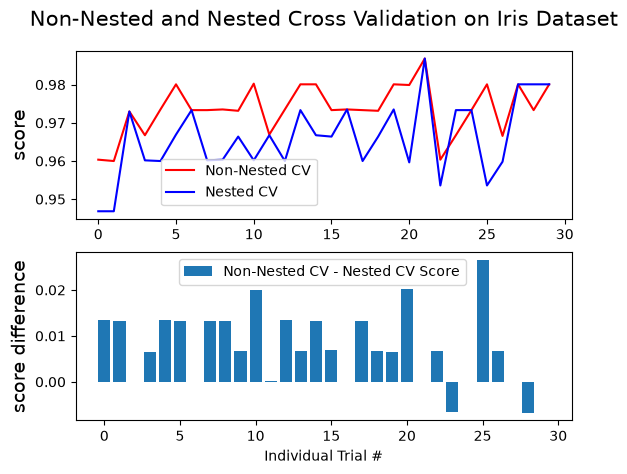

In [ ]:
# BEN: Copied from scikit-learn example: https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html

# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import numpy as np
from matplotlib import pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.svm import SVC

# Number of random trials
NUM_TRIALS = 30

# Load the dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# Set up possible values of parameters to optimize over
p_grid = {"C": [1, 10, 100], "gamma": [0.01, 0.1]}

# We will use a Support Vector Classifier with "rbf" kernel
svm = SVC(kernel="rbf")

# Arrays to store scores
non_nested_scores = np.zeros(NUM_TRIALS)
nested_scores = np.zeros(NUM_TRIALS)

# Loop for each trial
for i in range(NUM_TRIALS):
    # Choose cross-validation techniques for the inner and outer loops,
    # independently of the dataset.
    # E.g "GroupKFold", "LeaveOneOut", "LeaveOneGroupOut", etc.
    inner_cv = KFold(n_splits=4, shuffle=True, random_state=i)
    outer_cv = KFold(n_splits=4, shuffle=True, random_state=i)

    # Non_nested parameter search and scoring
    clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=outer_cv)
    clf.fit(X_iris, y_iris)
    non_nested_scores[i] = clf.best_score_

    # Nested CV with parameter optimization
    clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=inner_cv)
    nested_score = cross_val_score(clf, X=X_iris, y=y_iris, cv=outer_cv)
    nested_scores[i] = nested_score.mean()

score_difference = non_nested_scores - nested_scores

print(
    "Average difference of {:6f} with std. dev. of {:6f}.".format(
        score_difference.mean(), score_difference.std()
    )
)

# Plot scores on each trial for nested and non-nested CV
plt.figure()
plt.subplot(211)
(non_nested_scores_line,) = plt.plot(non_nested_scores, color="r")
(nested_line,) = plt.plot(nested_scores, color="b")
plt.ylabel("score", fontsize="14")
plt.legend(
    [non_nested_scores_line, nested_line],
    ["Non-Nested CV", "Nested CV"],
    bbox_to_anchor=(0, 0.4, 0.5, 0),
)
plt.title(
    "Non-Nested and Nested Cross Validation on Iris Dataset",
    x=0.5,
    y=1.1,
    fontsize="15",
)

# Plot bar chart of the difference.
plt.subplot(212)
difference_plot = plt.bar(range(NUM_TRIALS), score_difference)
plt.xlabel("Individual Trial #")
plt.legend(
    [difference_plot],
    ["Non-Nested CV - Nested CV Score"],
    bbox_to_anchor=(0, 1, 0.8, 0),
)
plt.ylabel("score difference", fontsize="14")

plt.show()

In [ ]:
# BEN: Copied from scikit-learn example: https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html

# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import numpy as np
from matplotlib import pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.svm import SVC

# Number of random trials
NUM_TRIALS = 30

# Load the dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# Set up possible values of parameters to optimize over
p_grid = {"C": [1, 10, 100], "gamma": [0.01, 0.1]}

# We will use a Support Vector Classifier with "rbf" kernel
svm = SVC(kernel="rbf")

# Arrays to store scores
non_nested_scores = np.zeros(NUM_TRIALS)
nested_scores = np.zeros(NUM_TRIALS)

# Loop for each trial
for i in range(NUM_TRIALS):
    # Choose cross-validation techniques for the inner and outer loops,
    # independently of the dataset.
    # E.g "GroupKFold", "LeaveOneOut", "LeaveOneGroupOut", etc.
    inner_cv = KFold(n_splits=4, shuffle=True, random_state=i)
    outer_cv = KFold(n_splits=4, shuffle=True, random_state=i)

    # Non_nested parameter search and scoring
    clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=outer_cv)
    clf.fit(X_iris, y_iris)
    non_nested_scores[i] = clf.best_score_

    # Nested CV with parameter optimization
    clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=inner_cv)
    nested_score = cross_val_score(clf, X=X_iris, y=y_iris, cv=outer_cv)
    nested_scores[i] = nested_score.mean()

score_difference = non_nested_scores - nested_scores

print(
    "Average difference of {:6f} with std. dev. of {:6f}.".format(
        score_difference.mean(), score_difference.std()
    )
)

# Plot scores on each trial for nested and non-nested CV
plt.figure()
plt.subplot(211)
(non_nested_scores_line,) = plt.plot(non_nested_scores, color="r")
(nested_line,) = plt.plot(nested_scores, color="b")
plt.ylabel("score", fontsize="14")
plt.legend(
    [non_nested_scores_line, nested_line],
    ["Non-Nested CV", "Nested CV"],
    bbox_to_anchor=(0, 0.4, 0.5, 0),
)
plt.title(
    "Non-Nested and Nested Cross Validation on Iris Dataset",
    x=0.5,
    y=1.1,
    fontsize="15",
)

# Plot bar chart of the difference.
plt.subplot(212)
difference_plot = plt.bar(range(NUM_TRIALS), score_difference)
plt.xlabel("Individual Trial #")
plt.legend(
    [difference_plot],
    ["Non-Nested CV - Nested CV Score"],
    bbox_to_anchor=(0, 1, 0.8, 0),
)
plt.ylabel("score difference", fontsize="14")

plt.show()